# Đánh giá tournament và sức chơi

## Mục tiêu
Đọc kết quả tournament có sẵn theo agent, đối thủ, màu và ruleset; kiểm tra dữ liệu/protocol trước khi đối chiếu checkpoint. Notebook **chỉ đọc** CSV, tài liệu và SQLite; không gọi training, self-play, tournament hay sửa artifact. Kết quả hiển thị phụ thuộc dữ liệu thật có trên máy đang chạy.

## Nguồn và giới hạn
- `scripts/tournament.py` — lập cặp đổi màu, lưu W/D/L, opening, seed và telemetry.
- `az/logging_v2.py` — schema `experiments`, `agents`, `matches`, `games`, `moves`, `events`; dữ liệu ván nằm trong `games.payload_json`.
- `SPEC.md` §10.1–10.2, §12 — protocol, tách Normal/Renju, score `(W + 0.5D)/N`, bootstrap theo opening pair; full multi-agent Elo vẫn Planned.
- `docs/analysis/50k-quality-validation.md` — phép so sánh 50k/40k và 50k/Heuristic, protocol và Davidson CI.
- `experiment_results.csv` — CSV hiện có với cột tiếng Việt; kết quả lịch sử tổng hợp, không thay thế game-level logs. `working_details.csv` có metadata/metric lịch sử với nguồn local và bản sao; không cộng các dòng snapshot/run.

SQLite/checkpoint/logs bị Git ignore. Nếu thiếu trong clone, các game-level bảng/biểu đồ tương ứng sẽ báo thiếu và notebook vẫn chạy với CSV/tài liệu có trong Git; không tái tạo hay giả lập kết quả.

In [1]:
%matplotlib inline
from pathlib import Path
from contextlib import closing
import json, sqlite3
import pandas as pd
import matplotlib.pyplot as plt

# Hỗ trợ chạy từ thư mục gốc hoặc notebooks/.
HERE = Path.cwd().resolve()
ROOT = next((p for p in (HERE, *HERE.parents) if (p / 'SPEC.md').is_file()), HERE.parent)
STYLE = 'seaborn-v0_8-whitegrid'
if STYLE in plt.style.available:
    plt.style.use(STYLE)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11})
FIGSIZE = (11, 5)
print(f'Repo root: {ROOT}')

Repo root: D:\PycharmProject\SGU-TriTueNhanTaoNangCao\AlphaZero_Gomoku


## Protocol và cách đọc kết quả
Tournament hiện tại ghép hai ván trên cùng opening/seed và đổi bên cầm Đen; các ván trong một opening pair không độc lập. AZ protocol v1 đề xuất 200 simulations, temperature 0, root noise tắt; screening 100 ván chỉ là sàng lọc, main 400 ván. Ngân sách `sims:N` và `time:S` không tương đương giữa thuật toán.

Chỉ tính game có winner `black`, `white` hoặc `draw`. W/D/L luôn theo agent; màu lấy theo ghế trong ván. Báo cáo WDL mô tả mẫu, không phải ước lượng xác suất độc lập. Khoảng Wilson score có thể có sẵn ở summary code nhưng không phản ánh phụ thuộc opening pair; không dùng để tuyên bố tương đương. Normal và Renju là hai pool riêng.

In [2]:
# Chỉ mở SQLite ở URI mode=ro. Không tạo DB nếu file thiếu.
DB_PATHS = {
    'tournament-local': ROOT / 'data/tournament.sqlite',
    'eval-50k-vs-40k': ROOT / 'data/eval_50k_vs_40k_400.sqlite',
    'eval-50k-vs-heuristic': ROOT / 'data/eval_50k_vs_heuristic_400.sqlite',
    'screen-60k-vs-heuristic': ROOT / 'data/az_35k_heuristic_screen_20261120.sqlite',
}
def read_games(db_path, source_name):
    if not db_path.is_file():
        return [], f'{db_path.relative_to(ROOT)}: không có (local/ignored hoặc chưa cung cấp)'
    uri = db_path.resolve().as_uri() + '?mode=ro'
    with closing(sqlite3.connect(uri, uri=True)) as con:
        con.row_factory = sqlite3.Row
        tables = {r[0] for r in con.execute("SELECT name FROM sqlite_master WHERE type='table'")}
        needed = {'experiments', 'agents', 'games'}
        if not needed <= tables:
            return [], f'{db_path.relative_to(ROOT)}: thiếu bảng {sorted(needed - tables)}'
        # Grouping happens downstream; avoid a SQL sort that may need writable temp storage.
        sql = '''SELECT g.experiment_id, g.local_game_id, g.match_id, g.rule_set, g.winner,
                        g.end_reason, g.moves_count, g.duration_sec, g.payload_json,
                        b.label AS black_agent, b.algorithm AS black_algorithm,
                        b.checkpoint_sha256 AS black_sha, b.config_json AS black_config,
                        w.label AS white_agent, w.algorithm AS white_algorithm,
                        w.checkpoint_sha256 AS white_sha, w.config_json AS white_config,
                        e.seed AS experiment_seed, e.backend AS experiment_backend,
                        e.config_json AS experiment_config
                 FROM games g
                 JOIN agents b ON b.agent_id=g.black_agent_id
                 JOIN agents w ON w.agent_id=g.white_agent_id
                 JOIN experiments e ON e.experiment_id=g.experiment_id'''
        rows = [dict(r) for r in con.execute(sql)]
    for row in rows:
        row['source'] = source_name
        row['payload'] = json.loads(row.pop('payload_json') or '{}')
        row['experiment_config'] = json.loads(row['experiment_config'] or '{}')
        row['black_config'] = json.loads(row['black_config'] or '{}')
        row['white_config'] = json.loads(row['white_config'] or '{}')
    return rows, None

raw_games, missing_sources = [], []
seen_game_ids = set()
duplicate_game_rows = 0
for source, path in DB_PATHS.items():
    rows, missing = read_games(path, source)
    for row in rows:
        key = (row['experiment_id'], row['local_game_id'])
        if key in seen_game_ids:
            duplicate_game_rows += 1
            continue
        seen_game_ids.add(key)
        raw_games.append(row)
    if missing:
        missing_sources.append(missing)

if raw_games:
    game_df = pd.DataFrame(raw_games)
    display(game_df.groupby(['source', 'experiment_id', 'rule_set'], as_index=False).agg(
        games=('local_game_id', 'nunique'), checkpoint_hashes=('black_sha', 'nunique'),
        experiments=('experiment_id', 'nunique')))
else:
    game_df = pd.DataFrame()
    print('Không có SQLite tournament game-level khả dụng.')
print(f'Số bản ghi game trùng experiment_id/local_game_id bị bỏ qua: {duplicate_game_rows}')
for message in missing_sources:
    print('Thiếu:', message)


,source,experiment_id,rule_set,games,checkpoint_hashes,experiments
0,eval-50k-vs-40k,eval50k-vs40k-400-seed508001,normal,400,2,1
1,eval-50k-vs-heuristic,eval50k-vs-heuristic-400-seed508001,normal,400,1,1
2,screen-60k-vs-heuristic,az-35k-vs-heuristic-screen-20261120,normal,100,1,1
3,tournament-local,az-15k-vs-heuristic-20261119-az_v0,normal,100,1,1
4,tournament-local,az-15k-vs-heuristic-20261119-az_v1_tactical,normal,100,1,1
5,tournament-local,az-15k-vs-heuristic-20261119-az_v1_threat,normal,100,1,1
6,tournament-local,az-normal-cpp-remaining-5k-20261122-promotion-...,normal,100,1,1
7,tournament-local,az-normal-cpp-remaining-5k-20261122-promotion-...,normal,100,1,1
8,tournament-local,az-normal-cpp-remaining-5k-20261122-promotion-...,normal,100,1,1
9,tournament-local,az-normal-cpp-remaining-5k-20261122-promotion-...,normal,100,1,1


Số bản ghi game trùng experiment_id/local_game_id bị bỏ qua: 0


In [3]:
# Mỗi game tạo hai góc nhìn; game trùng theo experiment_id/local_game_id chỉ giữ bản đầu.
perspectives = []
for g in raw_games:
    p = g['payload']
    winner = str(g['winner']).lower()
    if winner not in {'black', 'white', 'draw'}:
        continue  # game chưa hoàn tất/unknown không phải W/D/L
    for color, seat_color, label_key, algo_key, sha_key, opp_color in (
        ('Đen', 'black', 'black_agent', 'black_algorithm', 'black_sha', 'white'),
        ('Trắng', 'white', 'white_agent', 'white_algorithm', 'white_sha', 'black'),
    ):
        label = g[label_key]
        outcome = 'D' if winner == 'draw' else ('W' if winner == seat_color else 'L')
        opponent = g[opp_color + '_agent']
        perspectives.append({
            'source': g['source'], 'experiment_id': g['experiment_id'],
            'ruleset': g['rule_set'], 'agent': label, 'algorithm': g[algo_key],
            'checkpoint_sha256': g[sha_key] or 'không có SHA', 'opponent': opponent,
            'color': color, 'outcome': outcome, 'end_reason': g['end_reason'],
            'pair_id': g['match_id'], 'budget': g['experiment_config'].get('budget'),
            'opening_plies': p.get('opening_plies'), 'seed': g['experiment_seed'],
        })

perspective_df = pd.DataFrame(perspectives)
if not perspective_df.empty:
    wdl = (perspective_df.pivot_table(index=['source','experiment_id','ruleset','agent',
              'checkpoint_sha256','opponent','color'], columns='outcome', values='pair_id',
              aggfunc='count', fill_value=0).reset_index())
    for col in ['W','D','L']:
        if col not in wdl: wdl[col] = 0
    wdl['N'] = wdl[['W','D','L']].sum(axis=1)
    wdl['score'] = (wdl['W'] + 0.5 * wdl['D']) / wdl['N'].where(wdl['N'] != 0)
    display(wdl.sort_values(['source','experiment_id','agent','color']))
else:
    wdl = pd.DataFrame()
    print('Chưa có game records để lập W/D/L.')

outcome,source,experiment_id,ruleset,agent,checkpoint_sha256,opponent,color,D,L,W,N,score
0,eval-50k-vs-40k,eval50k-vs40k-400-seed508001,normal,az_v0@checkpoint=checkpoints/az_25k_continuati...,89fddabc55a1b79360ed91e0f1263405139ae81e9691e0...,az_v0@checkpoint=checkpoints/az_25k_continuati...,Trắng,4,157,39,200,0.2050
1,eval-50k-vs-40k,eval50k-vs40k-400-seed508001,normal,az_v0@checkpoint=checkpoints/az_25k_continuati...,89fddabc55a1b79360ed91e0f1263405139ae81e9691e0...,az_v0@checkpoint=checkpoints/az_25k_continuati...,Đen,1,121,78,200,0.3925
2,eval-50k-vs-40k,eval50k-vs40k-400-seed508001,normal,az_v0@checkpoint=checkpoints/az_25k_continuati...,28ea9001fd83c1c7b4d62117a4d7e4a1726c95eb02b8a3...,az_v0@checkpoint=checkpoints/az_25k_continuati...,Trắng,1,78,121,200,0.6075
3,eval-50k-vs-40k,eval50k-vs40k-400-seed508001,normal,az_v0@checkpoint=checkpoints/az_25k_continuati...,28ea9001fd83c1c7b4d62117a4d7e4a1726c95eb02b8a3...,az_v0@checkpoint=checkpoints/az_25k_continuati...,Đen,4,39,157,200,0.7950
4,eval-50k-vs-heuristic,eval50k-vs-heuristic-400-seed508001,normal,az_v0@checkpoint=checkpoints/az_25k_continuati...,28ea9001fd83c1c7b4d62117a4d7e4a1726c95eb02b8a3...,heuristic,Trắng,0,113,87,200,0.4350
...,...,...,...,...,...,...,...,...,...,...,...,...
328,tournament-local,t35-rerun-20261124-renju-fixed,renju,random,không có SHA,az_renju,Trắng,0,50,0,50,0.0000
330,tournament-local,t35-rerun-20261124-renju-fixed,renju,random,không có SHA,heuristic,Trắng,0,50,0,50,0.0000
327,tournament-local,t35-rerun-20261124-renju-fixed,renju,random,không có SHA,alphabeta,Đen,0,49,1,50,0.0200
329,tournament-local,t35-rerun-20261124-renju-fixed,renju,random,không có SHA,az_renju,Đen,0,50,0,50,0.0000


## W/D/L theo agent, đối thủ và màu
Bảng trên giữ nguyên source database, experiment ID, ruleset, SHA checkpoint, đối thủ và màu. Khi dùng `data/tournament.sqlite`, cùng DB có thể chứa nhiều protocol/run; không cộng chúng thành một tỷ lệ chung. Chênh lệch Black/White là mô tả theo màu của từng cohort, không tự động là hiệu ứng màu nhân quả. Illegal move là loss của agent phạm luật theo runner; draw được giữ là D.

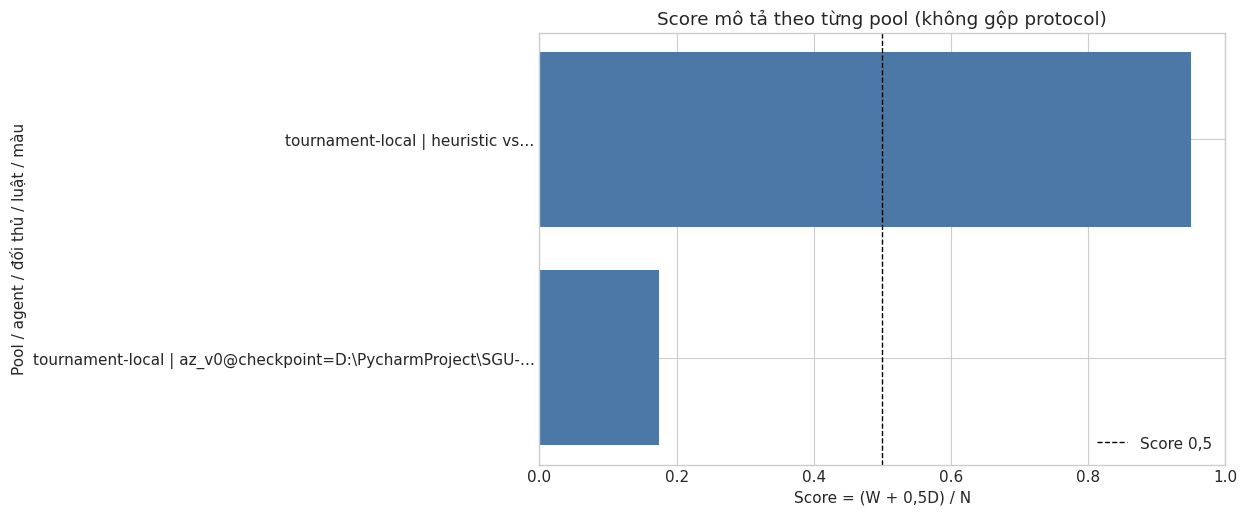

In [4]:
if not wdl.empty:
    plot_df = wdl.sort_values('N', ascending=False).head(12).copy()
    plot_df['label'] = plot_df.apply(lambda r: f"{r['source']} | {r['agent']} vs {r['opponent']} | {r['ruleset']} | {r['color']}", axis=1)
    ylabel = 'Pool / agent / đối thủ / luật / màu'
else:
    csv_path = ROOT / 'experiment_results.csv'
    required = {'Mã thí nghiệm','Nhóm thí nghiệm','Số ván','A thắng','Hòa','A thua','Bộ luật','Phương pháp hoặc tác tử A','Đối thủ B'}
    if csv_path.is_file():
        summary = pd.read_csv(csv_path, encoding='utf-8-sig')
        if required <= set(summary.columns):
            plot_df = summary[summary['Nhóm thí nghiệm'].astype(str).str.contains('đánh giá checkpoint', case=False, na=False)].copy()
            for col in ['Số ván','A thắng','Hòa','A thua']:
                plot_df[col] = pd.to_numeric(plot_df[col], errors='coerce')
            plot_df = plot_df.dropna(subset=['Số ván','A thắng','Hòa','A thua'])
            plot_df = plot_df[plot_df['Số ván'] > 0].copy()
            plot_df['score'] = (plot_df['A thắng'] + 0.5 * plot_df['Hòa']) / plot_df['Số ván']
            plot_df['label'] = plot_df.apply(lambda r: f"CSV | {r['Mã thí nghiệm']} | {r['Phương pháp hoặc tác tử A']} vs {r['Đối thủ B']} | {r['Bộ luật']}", axis=1)
            display(plot_df[['Mã thí nghiệm','Phương pháp hoặc tác tử A','Đối thủ B','Bộ luật','Số ván','A thắng','Hòa','A thua','score']])
            ylabel = 'CSV summary / agent A / đối thủ / luật'
            print('Fallback CSV chỉ có W/D/L tổng hợp; không có game-level màu hoặc opening pair.')
        else:
            plot_df = pd.DataFrame()
            print('CSV tracked thiếu cột W/D/L cần thiết để vẽ.')
    else:
        plot_df = pd.DataFrame()
        print('Không có SQLite hoặc CSV tracked chứa W/D/L; không dựng số liệu thay thế.')

if not plot_df.empty:
    import textwrap
    fig, ax = plt.subplots(figsize=(14, max(5, len(plot_df) * 0.45)))
    labels = [textwrap.shorten(label, width=64, placeholder='…') for label in plot_df['label'][::-1]]
    ax.barh(labels, plot_df['score'][::-1], color='#4c78a8')
    ax.axvline(0.5, color='black', linestyle='--', linewidth=1, label='Score 0,5')
    ax.set_xlim(0, 1); ax.set_xlabel('Score = (W + 0,5D) / N'); ax.set_ylabel(ylabel)
    ax.set_title('Score mô tả theo từng pool (không gộp protocol)'); ax.legend()
    fig.subplots_adjust(left=0.48, right=0.97, bottom=0.12, top=0.92)
    plt.show()

## Đối chiếu checkpoint có điều kiện
Chỉ đối chiếu khi đồng nhất luật, opponent/model identity, budget/search settings, backend, opening/seed scheme, opening plies và evaluation protocol; mỗi checkpoint cần SHA-256. Kết quả Normal và Renju không cùng rating pool. Không thay SHA bằng tên `latest.pt` hoặc mốc iteration; không xem cùng số games là cùng protocol. Nếu chỉ có W/D/L tổng hợp CSV thì không thể kiểm tra ghép cặp opening, màu hay identity đầy đủ.

### Ví dụ có nguồn ghi nhận (không gộp)
`docs/analysis/50k-quality-validation.md` ghi nhận hai experiment độc lập, cùng Normal / Python MCTS 200 / temperature 0 / no root noise / opening 4 ply / seed scheme `paired-crc32`: 50k vs 40k (400 game, 200 pair) và 50k vs Heuristic (400 game, 200 pair). Đây là hai matchup khác opponent nên **không cộng** hoặc so hai score như cùng pool. Với so sánh trực tiếp 50k–40k, ΔElo pairwise +149,91 [114,88; 188,51]; không phải Elo tuyệt đối. So với Heuristic, ΔElo +25,36 [−7,86; +58,00], CI chứa 0: chưa đủ bằng chứng mạnh hơn Heuristic. CI dùng paired opening-cluster bootstrap 10.000 lần, seed 508001. Những con số được trích từ report, không tự tính lại nếu thiếu DB/checkpoint.

Mốc 60k danh nghĩa là screening 100 game với protocol 4 opening plies/backend và danh tính khác; không ghép với 400-game cohort. Lịch sử 25k-vs-Heuristic 46/0/354 cũng không thể so trực tiếp với 15k 6/0/94: khác backend, seed, số game và code/provenance. Không có full multi-agent Davidson leaderboard được suy ra ở đây.

In [5]:
csv_path = ROOT / 'experiment_results.csv'
if csv_path.is_file():
    csv = pd.read_csv(csv_path, encoding='utf-8-sig')
    required = {'Mã thí nghiệm','Nhóm thí nghiệm','Số ván','A thắng','Hòa','A thua','Bộ luật','Nguồn SQLite local'}
    print('Cột CSV có:', list(csv.columns))
    if required <= set(csv.columns):
        eval_csv = csv[csv['Nhóm thí nghiệm'].astype(str).str.contains('đánh giá checkpoint', case=False, na=False)].copy()
        display(eval_csv[['Mã thí nghiệm','Tên thí nghiệm','Bộ luật','Số ván','A thắng','Hòa','A thua','Tỷ lệ điểm của A (%)','Mã run','Nguồn SQLite local','Nguồn trong Git','Ghi chú']])
        print('CSV là catalog/tóm tắt lịch sử. Các dòng không có game-level identity/opening không dùng để tính strata hoặc paired CI.')
    else:
        print('Schema CSV khác dự kiến; không áp dụng mapping cột.')
else:
    print('Không có experiment_results.csv; notebook tiếp tục bằng SQLite/docs nếu sẵn có.')

Cột CSV có: ['Mã thí nghiệm', 'Tên thí nghiệm', 'Nhóm thí nghiệm', 'Phân loại bằng chứng', 'Thời gian', 'Bộ luật', 'Phiên bản mô hình', 'Phương pháp hoặc tác tử A', 'Đối thủ B', 'Backend', 'Ngân sách tìm kiếm', 'Mục đích', 'Số ván', 'A thắng', 'Hòa', 'A thua', 'A thắng khi Đen', 'A thắng khi Trắng', 'Tỷ lệ thắng của A (%)', 'Tỷ lệ điểm của A (%)', 'Chỉ số', 'Giá trị đầu ghi nhận', 'Giá trị cuối ghi nhận', 'Giá trị', 'Đơn vị', 'Ván self-play bổ sung của nhánh', 'Ván lũy kế danh nghĩa theo nhãn checkpoint', 'Mã run', 'Nguồn SQLite local', 'Nguồn trong Git', 'Kết luận', 'Ghi chú']


,Mã thí nghiệm,Tên thí nghiệm,Bộ luật,Số ván,A thắng,Hòa,A thua,Tỷ lệ điểm của A (%),Mã run,Nguồn SQLite local,Nguồn trong Git,Ghi chú
69,eval_50k_vs_40k,Normal 50k so với 40k,normal,400.0,278.0,5.0,117.0,70.125,eval50k-vs40k-400-seed508001,data/eval_50k_vs_40k_400.sqlite (không theo dõ...,docs/analysis/50k-quality-validation.md,W/D/L/score đối chiếu trực tiếp với 400 games;...
70,eval_50k_vs_heuristic,Normal 50k so với Heuristic,normal,400.0,213.0,3.0,184.0,53.625,eval50k-vs-heuristic-400-seed508001,data/eval_50k_vs_heuristic_400.sqlite (không t...,docs/analysis/50k-quality-validation.md,W/D/L/score đối chiếu trực tiếp với 400 games;...
71,eval_60k_vs_heuristic,Normal 60k danh nghĩa so với Heuristic,normal,100.0,55.0,1.0,44.0,55.500,az-35k-vs-heuristic-screen-20261120,data/az_35k_heuristic_screen_20261120.sqlite (...,docs/analysis/60k-vs-heuristic-100-games-20261...,DB 100 games; Elo và CI theo báo cáo. Mốc 60k ...
72,eval_1500_vs_heuristic,Normal iteration 1500 so với Heuristic,normal,400.0,295.0,0.0,105.0,73.750,az-strength-1500-vs-heuristic-400-20261123,data/tournament.sqlite (không theo dõi trong Git),report/report.md mục 6.5,"DB 400 games, W/D/L xác nhận. Elo +178.92 theo..."
73,eval_renju500_vs_heuristic,Renju 500 so với Heuristic,renju,100.0,0.0,0.0,100.0,0.000,NaN,Không đủ thông tin SQLite trong nguồn báo cáo,report/report.md mục 5.6,W/D/L theo audit; checkpoint 500 không có sour...
74,eval_renju1500_vs_heuristic,Renju 1500 so với Heuristic,renju,100.0,32.0,0.0,68.0,32.000,NaN,Không đủ thông tin SQLite trong nguồn báo cáo,report/report.md mục 5.6,"W/D/L theo audit; Đen thắng 13/50, Trắng thắng..."


CSV là catalog/tóm tắt lịch sử. Các dòng không có game-level identity/opening không dùng để tính strata hoặc paired CI.


## Kết luận và điều kiện tái chạy
Các bảng/biểu đồ trên chỉ mô tả game records cục bộ được tìm thấy khi notebook chạy. CSV trong Git chứa các tổng kết nhưng không chứng minh mỗi game hoặc cho phép paired analysis. Chỉ so checkpoint với SHA/protocol rõ và game-level records matched; giữ từng opponent/ruleset/pool tách biệt. Kết quả 50k/40k và Heuristic chỉ áp dụng protocol/openings được mô tả trong report.

Để phân tích đầy đủ sau clone cần cung cấp các artifact bị bỏ qua khỏi Git: `data/tournament.sqlite`, các DB riêng `data/eval_50k_vs_40k_400.sqlite`, `data/eval_50k_vs_heuristic_400.sqlite` (hoặc DB gốc tương ứng), và checkpoint immutable đúng SHA cùng manifests/config/log khi cần tái dựng identity. Cần Jupyter, pandas, matplotlib; không cần training dependencies nếu chỉ đọc SQLite/CSV. Nếu thiếu DB, chỉ còn summary CSV/docs: không thể tái tạo WDL theo màu, ruleset, opponent và opening pair. Không chạy training/tournament, không sửa dữ liệu gốc.